# **Bellabeat Case Study — Analyze Phase**

## Objective

The purpose of this phase is to analyze the cleaned Fitbit datasets to identify trends and relationships in smart device usage. The analysis focuses on physical activity, step counts, calorie expenditure, sleep patterns, and heart rate.

The findings will be used to explore how smart device usage trends could apply to Bellabeat customers and help inform potential marketing strategies.

## Data Overview

The analysis uses six cleaned and consolidated datasets derived from 12 original Fitbit datasets collected across two overlapping time periods.

## Analysis Workflow
1. Import and inspect the cleaned datasets.
2. Calculate descriptive statistics.
3. Identify smart device usage trends.
4. Examine relationships between variables.
5. Interpret findings in relation to Bellabeat.
6. Export analytical summaries for visualization and reporting.


## **Step 1: Import and Inspect Cleaned Datasets**

### Purpose
To load the cleaned Fitbit datasets and verify that they are properly organized and ready for analysis.


In [1]:
# ==================================================
# Step 1A - Import Required Libraries
# ==================================================

# Import Pandas for data manipulation and analysis
import pandas as pd

# Import NumPy for numerical calculations
import numpy as np

# Import Path for managing file locations
from pathlib import Path

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")


Libraries imported successfully.
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
# ==================================================
# Step 1B - Locate Cleaned Datasets
# ==================================================

# Identify the current working directory
project_dir = Path.cwd()

print("Current working directory:")
print(project_dir)

# Search for CSV files in the project folder
# and its subfolders
csv_files = sorted(project_dir.rglob("*.csv"))

# Display the number of files found
print("\nCSV files found:", len(csv_files))

# Display the location of each CSV file
for file in csv_files:
    print(file.relative_to(project_dir))


Current working directory:
/Users/isandoval/Desktop/Bellabeat_Case_Study

CSV files found: 37
Cleaned_Data/dailyActivity_calorie_analysis.csv
Cleaned_Data/dailyActivity_clean.csv
Cleaned_Data/heartRate_clean.csv
Cleaned_Data/hourlyCalories_clean.csv
Cleaned_Data/hourlyIntensities_clean.csv
Cleaned_Data/hourlySteps_clean.csv
Cleaned_Data/minuteSleep_clean.csv
Cleaned_Data/sleepLog_summary_clean.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/heartrate_seconds_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/hourlyCalories_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/hourlyIntensities_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/hourlySteps_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/minuteCaloriesNarrow_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/minuteIntensitiesNarrow_merged.csv
Original_Data/Fitabase Data 3.12.16-4.11.16/minuteMETsNarrow_merged.csv
Original_Data/Fitaba

In [3]:
# ==================================================
# Step 1C - Load Cleaned Datasets
# ==================================================

# Define the folder containing cleaned datasets
clean_dir = project_dir / "Cleaned_Data"

# Load the cleaned datasets needed for initial analysis
daily_activity = pd.read_csv(
    clean_dir / "dailyActivity_clean.csv"
)

daily_calories = pd.read_csv(
    clean_dir / "dailyActivity_calorie_analysis.csv"
)

hourly_steps = pd.read_csv(
    clean_dir / "hourlySteps_clean.csv"
)

hourly_intensities = pd.read_csv(
    clean_dir / "hourlyIntensities_clean.csv"
)

hourly_calories = pd.read_csv(
    clean_dir / "hourlyCalories_clean.csv"
)

sleep_logs = pd.read_csv(
    clean_dir / "sleepLog_summary_clean.csv"
)

# Store datasets in a dictionary for easier inspection
datasets = {
    "Daily Activity": daily_activity,
    "Daily Calorie Analysis": daily_calories,
    "Hourly Steps": hourly_steps,
    "Hourly Intensities": hourly_intensities,
    "Hourly Calories": hourly_calories,
    "Sleep Logs": sleep_logs
}

print("Datasets loaded successfully.")


Datasets loaded successfully.


In [4]:
# ==================================================
# Step 1D - Inspect Dataset Dimensions
# ==================================================

# Display rows and columns for each dataset
for name, df in datasets.items():

    print(f"\nDataset: {name}")
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")



Dataset: Daily Activity
Rows: 1,373
Columns: 21

Dataset: Daily Calorie Analysis
Rows: 1,367
Columns: 21

Dataset: Hourly Steps
Rows: 46,008
Columns: 10

Dataset: Hourly Intensities
Rows: 46,008
Columns: 10

Dataset: Hourly Calories
Rows: 46,008
Columns: 10

Dataset: Sleep Logs
Rows: 1,007
Columns: 19


In [5]:
# ==================================================
# Step 1E - Inspect Column Names and Data Types
# ==================================================

# Loop through each dataset
for name, df in datasets.items():

    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"{'=' * 50}")

    # Display column names and their data types
    column_info = pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values
    })

    display(column_info)

    # Display the first three observations
    print("First three observations:")
    display(df.head(3))



Dataset: Daily Activity


,Column,Data Type
0,Id,int64
1,ActivityDate,object
2,TotalSteps,int64
3,TotalDistance,float64
4,TrackerDistance,float64
5,LoggedActivitiesDistance,float64
6,VeryActiveDistance,float64
7,ModeratelyActiveDistance,float64
8,LightActiveDistance,float64
9,SedentaryActiveDistance,float64


First three observations:


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,SourcePeriod,TotalRecordedMinutes,FlagZeroCalories,FlagZeroSteps,FlagMinutesBelow1440,FlagActivityWithoutSteps
0,1503960366,2016-03-25,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819,Period 1,1054,False,False,True,False
1,1503960366,2016-03-26,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154,Period 1,968,False,False,True,False
2,1503960366,2016-03-27,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944,Period 1,934,False,False,True,False



Dataset: Daily Calorie Analysis


...

,Id,ActivityHour,Calories,SourcePeriod,MissingHoursBefore,FlagAfterGap,FlagHighCalories,FlagHighCaloriesZeroSteps,ActivityDate,HourOfDay
0,1503960366,2016-03-12 00:00:00,48,Period 1,0,False,False,False,2016-03-12,0
1,1503960366,2016-03-12 01:00:00,48,Period 1,0,False,False,False,2016-03-12,1
2,1503960366,2016-03-12 02:00:00,48,Period 1,0,False,False,False,2016-03-12,2



Dataset: Sleep Logs


,Column,Data Type
0,Id,int64
1,logId,int64
2,StartTime,object
3,EndTime,object
4,SleepEndDate,object
5,RecordedMinutes,int64
6,RecordedHours,float64
7,ElapsedMinutes,float64
8,RecordingGaps,int64
9,State1Minutes,int64


First three observations:


,Id,logId,StartTime,EndTime,SleepEndDate,RecordedMinutes,RecordedHours,ElapsedMinutes,RecordingGaps,State1Minutes,State2Minutes,State3Minutes,TotalStateMinutes,State1Pct,State2Pct,State3Pct,FlagShortLog,FlagLongLog,FlagDuration961
0,1503960366,11114919637,2016-03-13 02:39:30,2016-03-13 09:44:30,2016-03-13,426,7.10,426.0,0,411,15,0,426,96.478873,3.521127,0.000000,False,False,False
1,1503960366,11126343681,2016-03-14 01:32:00,2016-03-14 07:57:00,2016-03-14,386,6.43,386.0,0,354,27,5,386,91.709845,6.994819,1.295337,False,False,False
2,1503960366,11134971215,2016-03-15 02:36:00,2016-03-15 08:10:00,2016-03-15,335,5.58,335.0,0,312,16,7,335,93.134328,4.776119,2.089552,False,False,False


In [6]:
# ==================================================
# Step 1F - Convert Date and Timestamp Columns
# ==================================================

# Identify date columns within each dataset
date_columns = {
    "Daily Activity": ["ActivityDate"],
    "Daily Calorie Analysis": ["ActivityDate"],
    "Hourly Steps": ["ActivityHour", "ActivityDate"],
    "Hourly Intensities": ["ActivityHour", "ActivityDate"],
    "Hourly Calories": ["ActivityHour", "ActivityDate"],
    "Sleep Logs": ["StartTime", "EndTime", "SleepEndDate"]
}

# Create an empty list to store conversion results
conversion_results = []

# Convert date columns to datetime format
for name, columns in date_columns.items():

    df = datasets[name]

    for col in columns:

        # Count missing values before conversion
        missing_before = df[col].isna().sum()

        # Convert text values into datetime
        df[col] = pd.to_datetime(
            df[col],
            errors="coerce"
        )

        # Count missing values after conversion
        missing_after = df[col].isna().sum()

        # Record the results
        conversion_results.append({
            "Dataset": name,
            "Column": col,
            "Data Type": str(df[col].dtype),
            "Invalid Conversions": missing_after - missing_before
        })

# Display a summary of the conversions
conversion_summary = pd.DataFrame(conversion_results)

display(conversion_summary)


,Dataset,Column,Data Type,Invalid Conversions
0,Daily Activity,ActivityDate,datetime64[ns],0
1,Daily Calorie Analysis,ActivityDate,datetime64[ns],0
2,Hourly Steps,ActivityHour,datetime64[ns],0
3,Hourly Steps,ActivityDate,datetime64[ns],0
4,Hourly Intensities,ActivityHour,datetime64[ns],0
5,Hourly Intensities,ActivityDate,datetime64[ns],0
6,Hourly Calories,ActivityHour,datetime64[ns],0
7,Hourly Calories,ActivityDate,datetime64[ns],0
8,Sleep Logs,StartTime,datetime64[ns],0
9,Sleep Logs,EndTime,datetime64[ns],0



### **Step 1 — Findings and Observations**

Six cleaned datasets were successfully imported into Python for analysis. The datasets include daily activity, daily calorie analysis, hourly steps, hourly intensities, hourly calories, and summarized sleep logs.

The dataset dimensions matched the validated results from the Process Phase, confirming that the correct cleaned files were loaded.

The variables were inspected to identify their column names and data types. Numerical measurements and quality flags were stored in appropriate formats. Eleven date and timestamp columns were converted to datetime format, with zero invalid conversions.

Overall, the datasets are properly organized and formatted for analysis. The next step is to calculate descriptive statistics and identify initial patterns in smart device usage.


## **Step 2: Descriptive Statistics**

### Purpose
To summarize Fitbit users' activity, calorie expenditure, and sleep measurements using descriptive statistics.

In [7]:
# ==================================================
# Step 2A - Daily Activity Descriptive Statistics
# ==================================================

# Select the daily activity measurements
activity_columns = [
    "TotalSteps",
    "TotalDistance",
    "VeryActiveMinutes",
    "FairlyActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes"
]

# Calculate descriptive statistics
activity_summary = daily_activity[
    activity_columns
].describe()

# Include the median in the summary
activity_summary.loc["median"] = daily_activity[
    activity_columns
].median()

# Select and organize the statistics
activity_summary = activity_summary.loc[
    ["count", "mean", "median", "std", "min", "max"]
]

# Transpose for easier interpretation
activity_summary = activity_summary.T

# Round results to two decimal places
activity_summary = activity_summary.round(2)

# Display the results
display(activity_summary)


,count,mean,median,std,min,max
TotalSteps,1373.0,7377.38,7142.00,5198.13,0.0,36019.00
TotalDistance,1373.0,5.29,5.03,3.99,0.0,28.03
VeryActiveMinutes,1373.0,19.87,2.00,31.82,0.0,210.00
FairlyActiveMinutes,1373.0,13.60,6.00,26.58,0.0,660.00
LightlyActiveMinutes,1373.0,188.10,196.00,113.10,0.0,720.00
SedentaryMinutes,1373.0,1001.35,1062.00,304.17,0.0,1440.00


### **Step 2A — Findings and Observations**

Descriptive statistics were calculated using 1,373 daily activity observations.

Users recorded an average of 7,377 steps per day, with a median of 7,142 steps. The relatively large standard deviation of 5,198 steps indicates considerable variation in daily activity.

Light physical activity accounted for substantially more recorded time than moderate or vigorous activity. Users averaged approximately 188 minutes of light activity, compared with 20 minutes of very active movement and 14 minutes of fairly active movement.

Average sedentary time was approximately 1,001 minutes per recorded day, although this measure should be interpreted cautiously because recording coverage varies.

Overall, the results suggest substantial variation in activity levels, with light activity and sedentary periods making up large portions of recorded daily behavior.


In [8]:
# ==================================================
# Step 2B - Daily Calorie Descriptive Statistics
# ==================================================

# Select daily calorie expenditure
calorie_column = "Calories"

# Calculate descriptive statistics
calorie_summary = daily_calories[
    calorie_column
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Convert the results into a DataFrame
calorie_summary = calorie_summary.to_frame(
    name="Daily Calories"
)

# Round results to two decimal places
calorie_summary = calorie_summary.round(2)

# Display the results
display(calorie_summary)


,Daily Calories
count,1367.00
mean,2304.88
median,2131.00
std,710.96
min,52.00
max,4900.00


### **Step 2B — Findings and Observations**

Daily calorie expenditure was analyzed using 1,367 observations, excluding six zero-calorie records identified during the Process Phase.

The average estimated daily calorie expenditure was 2,304.88 calories, while the median was 2,131 calories. The higher mean suggests that larger calorie values may influence the overall average.

The standard deviation of 710.96 calories indicates substantial variation in daily energy expenditure.

Recorded values ranged from 52 to 4,900 calories. The unusually low minimum may reflect incomplete recording and should be interpreted cautiously.

Overall, the findings suggest considerable differences in estimated daily calorie expenditure across recorded observations. Further analysis will investigate how calorie expenditure relates to physical activity.


In [10]:
# ==================================================
# Step 2C - Hourly Activity Descriptive Statistics
# ==================================================

# Select hourly activity measurements
hourly_measurements = {
    "Hourly Steps": hourly_steps["StepTotal"],
    "Total Intensity": hourly_intensities["TotalIntensity"],
    "Average Intensity": hourly_intensities["AverageIntensity"],
    "Hourly Calories": hourly_calories["Calories"]
}

# Calculate descriptive statistics
hourly_summary = pd.DataFrame({
    name: values.agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    for name, values in hourly_measurements.items()
})

# Transpose the table for easier interpretation
hourly_summary = hourly_summary.T

# Round the results to two decimal places
hourly_summary = hourly_summary.round(2)

# Display the summary table
display(hourly_summary)


,count,mean,median,std,min,max
Hourly Steps,46008.0,302.87,21.00,677.30,0.0,10565.0
Total Intensity,46008.0,11.42,2.00,20.72,0.0,180.0
Average Intensity,46008.0,0.19,0.03,0.35,0.0,3.0
Hourly Calories,46008.0,95.82,80.00,60.04,42.0,948.0


### **Step 2C — Findings and Observations**

Hourly activity statistics were calculated using 46,008 observations for each measurement.

Users recorded an average of 302.87 steps per hour, compared with a median of 21 steps. This substantial difference suggests a right-skewed distribution, with many hours of limited movement and fewer periods of high activity.

Hourly activity intensity showed a similar pattern. Average total intensity was 11.42, while the median was 2, indicating that most recorded hours had relatively low activity intensity.

Average estimated calorie expenditure was 95.82 calories per hour, with a median of 80 calories.

Unusually high values were also observed, including 10,565 steps and 948 estimated calories in a single hour. These measurements should be interpreted cautiously because potential outliers and recording limitations may influence the results.

Overall, the findings suggest that physical activity is unevenly distributed across recorded hours, with relatively low activity during many periods and substantially higher activity during others.


In [11]:
# ==================================================
# Step 2D - Sleep Descriptive Statistics
# ==================================================

# Select sleep measurements
sleep_columns = [
    "RecordedHours",
    "RecordedMinutes",
    "State1Minutes",
    "State2Minutes",
    "State3Minutes",
    "RecordingGaps"
]

# Calculate descriptive statistics
sleep_summary = sleep_logs[
    sleep_columns
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Transpose for easier interpretation
sleep_summary = sleep_summary.T

# Round results to two decimal places
sleep_summary = sleep_summary.round(2)

# Display the results
display(sleep_summary)


,count,mean,median,std,min,max
RecordedHours,1007.0,6.34,6.95,2.83,1.0,16.02
RecordedMinutes,1007.0,380.12,417.00,170.03,60.0,961.00
State1Minutes,1007.0,349.48,383.00,156.06,9.0,940.00
State2Minutes,1007.0,26.66,18.00,35.23,0.0,344.00
State3Minutes,1007.0,3.98,3.00,9.16,0.0,129.00
RecordingGaps,1007.0,0.00,0.00,0.00,0.0,0.00


### **Step 2D — Findings and Observations**

Sleep descriptive statistics were calculated using 1,007 summarized sleep logs.

The average recorded sleep-log duration was 6.34 hours, while the median was 6.95 hours. The lower mean suggests that shorter recorded periods may influence the overall average.

The standard deviation of 2.83 hours indicates substantial variability in recorded sleep duration. Individual logs ranged from 1.00 to 16.02 hours, including unusually short and long periods that require cautious interpretation.

Most recorded minutes were classified as State 1, followed by State 2 and State 3. These categories will be interpreted according to the dataset's sleep-state definitions.

No recording gaps were identified within the summarized sleep logs.

Overall, recorded sleep duration varied considerably across observations. Further examination of flagged sleep logs will help determine whether unusual recording durations influence the results.


In [12]:
# ==================================================
# Step 2E - Investigate Unusual Sleep Durations
# ==================================================

# Identify short, long, and unusually lengthy logs
sleep_flags = [
    "FlagShortLog",
    "FlagLongLog",
    "FlagDuration961"
]

# Count records flagged under each condition
flag_summary = pd.DataFrame({
    "Flag": sleep_flags,
    "Flagged Logs": [
        sleep_logs[col].sum()
        for col in sleep_flags
    ]
})

display(flag_summary)

# Identify logs with at least one duration flag
flagged_logs = sleep_logs[sleep_flags].any(axis=1)

print("Total flagged logs:", flagged_logs.sum())
print("Unflagged logs:", (~flagged_logs).sum())

# Compare original and unflagged sleep durations
sleep_comparison = pd.DataFrame({
    "All Sleep Logs": sleep_logs["RecordedHours"].agg(
        ["count", "mean", "median", "std"]
    ),
    "Unflagged Sleep Logs": sleep_logs.loc[
        ~flagged_logs, "RecordedHours"
    ].agg(["count", "mean", "median", "std"])
})

# Round results to two decimal places
sleep_comparison = sleep_comparison.round(2)

display(sleep_comparison)


,Flag,Flagged Logs
0,FlagShortLog,123
1,FlagLongLog,9
2,FlagDuration961,8


Total flagged logs: 132
Unflagged logs: 875


,All Sleep Logs,Unflagged Sleep Logs
count,1007.00,875.00
mean,6.34,6.93
median,6.95,7.25
std,2.83,2.13


### **Step 2E — Findings and Observations**

A sensitivity analysis was conducted to examine the influence of unusually short and long sleep logs on recorded sleep duration.

Of the 1,007 sleep logs, 132 unique logs (13.1%) were flagged for unusual durations, leaving 875 unflagged logs.

When flagged observations were excluded, average recorded sleep-log duration increased from 6.34 to 6.93 hours, while the median increased from 6.95 to 7.25 hours.

The standard deviation also decreased from 2.83 to 2.13 hours, indicating less variability among unflagged observations.

These findings suggest that unusual sleep durations influence the overall descriptive statistics. The unflagged dataset will be used for the primary sleep-duration analysis, while the complete dataset will be retained for comparison.

Flagged observations are not necessarily invalid and may include legitimate short or long sleep periods. Therefore, the results should be interpreted as recorded sleep-log durations rather than definitive measures of actual sleep.


In [14]:
# ==================================================
# Step 2F.1 - Inspect Heart Rate Dataset
# ==================================================

# Identify the cleaned heart rate file
heart_rate_path = clean_dir / "heartRate_clean.csv"

# Import only the first five observations
# to avoid loading the full dataset unnecessarily
heart_rate_preview = pd.read_csv(
    heart_rate_path,
    nrows=5
)

# Display column names and data types
heart_rate_info = pd.DataFrame({
    "Column": heart_rate_preview.columns,
    "Data Type": heart_rate_preview.dtypes.astype(str).values
})

print("Heart Rate Dataset - Column Information")
display(heart_rate_info)

# Display sample observations
print("First five observations:")
display(heart_rate_preview)


Heart Rate Dataset - Column Information


,Column,Data Type
0,Id,int64
1,Time,object
2,Value,int64
3,SourcePeriod,object
4,FlagBelow40,bool
5,Flag40to49,bool
6,FlagAbove180,bool
7,FlagAbove200,bool
8,SecondsSincePrevious,float64
9,BPMChange,float64


First five observations:


,Id,Time,Value,SourcePeriod,FlagBelow40,Flag40to49,FlagAbove180,FlagAbove200,SecondsSincePrevious,BPMChange,FlagRapidChange
0,2022484408,2016-04-01 07:54:00,93,Period 1,False,False,False,False,NaN,NaN,False
1,2022484408,2016-04-01 07:54:05,91,Period 1,False,False,False,False,5.0,-2.0,False
2,2022484408,2016-04-01 07:54:10,96,Period 1,False,False,False,False,5.0,5.0,False
3,2022484408,2016-04-01 07:54:15,98,Period 1,False,False,False,False,5.0,2.0,False
4,2022484408,2016-04-01 07:54:20,100,Period 1,False,False,False,False,5.0,2.0,False


In [15]:
# ==================================================
# Step 2F.2 - Heart Rate Descriptive Statistics
# ==================================================

# Select only the columns needed for analysis
heart_rate_columns = [
    "Id",
    "Value",
    "FlagBelow40",
    "Flag40to49",
    "FlagAbove180",
    "FlagAbove200",
    "FlagRapidChange"
]

# Load selected columns from the cleaned dataset
heart_rate = pd.read_csv(
    heart_rate_path,
    usecols=heart_rate_columns
)

# Display the number of observations
print("Total heart rate observations:", f"{len(heart_rate):,}")

# Count unique participants
print("Unique participants:", heart_rate["Id"].nunique())

# Calculate descriptive statistics
heart_rate_summary = heart_rate["Value"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Convert results into a DataFrame
heart_rate_summary = heart_rate_summary.to_frame(
    name="Heart Rate (BPM)"
)

# Round results to two decimal places
heart_rate_summary = heart_rate_summary.round(2)

# Display the results
display(heart_rate_summary)


Total heart rate observations: 3,614,915
Unique participants: 15


,Heart Rate (BPM)
count,3614915.00
mean,78.14
median,74.00
std,19.22
min,36.00
max,203.00


In [16]:
# ==================================================
# Step 2F.3 - Examine Heart Rate Quality Flags
# ==================================================

# Identify the heart rate quality flags
heart_rate_flags = [
    "FlagBelow40",
    "Flag40to49",
    "FlagAbove180",
    "FlagAbove200",
    "FlagRapidChange"
]

# Count flagged observations and calculate percentages
heart_rate_flag_summary = pd.DataFrame({
    "Flag": heart_rate_flags,
    "Flagged Observations": [
        heart_rate[col].sum()
        for col in heart_rate_flags
    ],
    "Percentage (%)": [
        heart_rate[col].mean() * 100
        for col in heart_rate_flags
    ]
})

# Round percentages to two decimal places
heart_rate_flag_summary["Percentage (%)"] = (
    heart_rate_flag_summary["Percentage (%)"].round(2)
)

# Display flag summary
display(heart_rate_flag_summary)

# Identify observations with at least one flag
any_heart_rate_flag = heart_rate[
    heart_rate_flags
].any(axis=1)

# Count flagged and unflagged observations
print(
    "Total flagged observations:",
    f"{any_heart_rate_flag.sum():,}"
)

print(
    "Unflagged observations:",
    f"{(~any_heart_rate_flag).sum():,}"
)

print(
    "Percentage flagged:",
    f"{any_heart_rate_flag.mean() * 100:.2f}%"
)


,Flag,Flagged Observations,Percentage (%)
0,FlagBelow40,37,0.00
1,Flag40to49,52977,1.47
2,FlagAbove180,250,0.01
3,FlagAbove200,13,0.00
4,FlagRapidChange,168,0.00


Total flagged observations: 53,429
Unflagged observations: 3,561,486
Percentage flagged: 1.48%


In [17]:
# ==================================================
# Step 2F.4 - Heart Rate Sensitivity Analysis
# ==================================================

# Calculate statistics using all heart rate observations
all_heart_rates = heart_rate["Value"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Calculate statistics using unflagged observations
unflagged_heart_rates = heart_rate.loc[
    ~any_heart_rate_flag, "Value"
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Combine results into a comparison table
heart_rate_comparison = pd.DataFrame({
    "All Observations": all_heart_rates,
    "Unflagged Observations": unflagged_heart_rates
})

# Round results to two decimal places
heart_rate_comparison = heart_rate_comparison.round(2)

# Display the comparison
display(heart_rate_comparison)

# Calculate the difference in average heart rate
mean_difference = (
    unflagged_heart_rates["mean"]
    - all_heart_rates["mean"]
)

print(
    f"Difference in mean heart rate: "
    f"{mean_difference:.2f} BPM"
)


,All Observations,Unflagged Observations
count,3614915.00,3561486.00
mean,78.14,78.60
median,74.00,75.00
std,19.22,18.95
min,36.00,50.00
max,203.00,180.00


Difference in mean heart rate: 0.46 BPM


### **Step 2F — Findings and Observations**

Heart-rate descriptive statistics were calculated using 3,614,915 observations from 15 participants.

The average recorded heart rate was 78.14 BPM, with a median of 74 BPM and a standard deviation of 19.22 BPM. Recorded measurements ranged from 36 to 203 BPM.

Quality-flag analysis identified 53,429 observations (1.48%) with at least one flagged condition. Most flagged measurements involved heart rates between 40 and 49 BPM.

A sensitivity analysis compared all observations with the 3,561,486 unflagged observations. After excluding flagged measurements, the mean increased slightly to 78.60 BPM, while the median increased to 75 BPM.

The difference in mean heart rate was only 0.46 BPM, suggesting that flagged measurements have limited influence on the overall average.

The complete dataset will be retained for the primary heart-rate analysis because flagged measurements are not necessarily invalid.

However, these findings should be interpreted cautiously because only 15 participants contributed heart-rate data, and participants may have unequal numbers of observations.



## **Step 3: Identify Smart-Device Usage Trends**

### Purpose
To investigate patterns in Fitbit users' physical activity and sleep behavior over time.

### Approach
- Examine daily step counts by day of the week.
- Identify hourly activity patterns.
- Compare activity intensity across different times of the day.
- Investigate differences in physical activity levels.
- Examine patterns in recorded sleep duration.

### Expected Outcome
Identify meaningful trends in smart-device usage that could help explain consumer activity and wellness behaviors.

These findings will support the Bellabeat business questions by highlighting potential opportunities for personalized wellness features and marketing strategies.


In [19]:
# ==================================================
# Step 3A - Daily Steps by Day of the Week
# ==================================================

# Create a copy to preserve the original DataFrame
daily_trends = daily_activity.copy()

# Extract the weekday name from ActivityDate
daily_trends["DayOfWeek"] = (
    daily_trends["ActivityDate"].dt.day_name()
)

# Define the correct weekday order
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# Calculate daily step statistics by weekday
weekday_summary = (
    daily_trends
    .groupby("DayOfWeek")["TotalSteps"]
    .agg(
        Observations="count",
        AverageSteps="mean",
        MedianSteps="median",
        StdSteps="std"
    )
    .reindex(weekday_order)
)

# Round the statistics to two decimal places
weekday_summary = weekday_summary.round(2)

# Display the results
display(weekday_summary)


,Observations,AverageSteps,MedianSteps,StdSteps
DayOfWeek,,,,
Monday,188,7541.32,7420.0,4995.20
Tuesday,201,7718.96,8135.0,4799.81
Wednesday,198,7547.58,7351.0,4963.66
Thursday,195,7268.30,7550.0,5045.59
Friday,199,7187.53,7157.0,4741.61
Saturday,199,7752.27,6637.0,6053.92
Sunday,193,6606.73,5600.0,5641.85


### **Step 3A — Findings and Observations**

Daily step counts were analyzed across 1,373 participant-day observations to identify differences in physical activity by day of the week.

Saturday had the highest average step count at 7,752 steps, closely followed by Tuesday at 7,719 steps. However, Tuesday had the highest median at 8,135 steps, suggesting that typical activity levels may differ from patterns suggested by the averages.

Sunday had the lowest average and median step counts, with approximately 6,607 and 5,600 steps, respectively.

Saturday and Sunday also showed the greatest variability in daily step counts, suggesting less consistent activity levels across weekend observations.

Overall, the findings suggest that physical activity varies by day of the week, with particularly high variability on weekends. Differences in participant coverage and repeated observations should be considered before generalizing these patterns.


In [20]:
# ==================================================
# Step 3B - Hourly Step Patterns
# ==================================================

# Create a copy of the cleaned hourly steps dataset
hourly_trends = hourly_steps.copy()

# Group step counts by hour of the day
hourly_step_summary = (
    hourly_trends
    .groupby("HourOfDay")
    .agg(
        Observations=("StepTotal", "count"),
        AverageSteps=("StepTotal", "mean"),
        MedianSteps=("StepTotal", "median"),
        StdSteps=("StepTotal", "std"),
        ZeroStepHours=(
            "StepTotal",
            lambda x: (x == 0).sum()
        )
    )
    .sort_index()
)

# Calculate percentage of observations with zero steps
hourly_step_summary["ZeroStepPct"] = (
    hourly_step_summary["ZeroStepHours"]
    / hourly_step_summary["Observations"]
    * 100
)

# Round results to two decimal places
hourly_step_summary = hourly_step_summary.round(2)

# Display hourly statistics
display(hourly_step_summary)


,Observations,AverageSteps,MedianSteps,StdSteps,ZeroStepHours,ZeroStepPct
HourOfDay,,,,,,
0,1935,43.36,0.0,147.22,1331,68.79
1,1934,21.88,0.0,89.64,1476,76.32
2,1934,13.69,0.0,68.10,1560,80.66
3,1933,6.85,0.0,39.89,1647,85.20
4,1931,11.11,0.0,58.12,1649,85.40
5,1931,34.93,0.0,182.32,1570,81.31
6,1930,148.24,0.0,413.20,1199,62.12
7,1930,282.65,3.0,582.82,959,49.69
8,1930,395.84,54.0,851.37,806,41.76


### **Step 3B — Findings and Observations**

Hourly step patterns were analyzed using 46,008 participant-hour observations.

Physical activity was lowest during overnight hours, particularly at 3 AM, when average steps reached only 6.85. More than 80% of observations between 2 AM and 5 AM recorded zero steps.

Average steps increased during the morning and remained relatively high around midday and early evening.

The highest average step counts occurred at 7 PM (554.89), 6 PM (550.27), and 12 PM (534.26). However, 6 PM had the highest median step count of 282, indicating that typical activity may differ from average activity.

Activity generally decreased after 7 PM, with average hourly steps falling to 112.09 by 11 PM.

Overall, the findings suggest that recorded physical activity follows a daily pattern, with relatively low movement overnight and higher activity during midday and early evening.

These patterns could help Bellabeat explore personalized activity reminders and wellness engagement strategies, although further analysis is needed before making recommendations.


In [21]:
# ==================================================
# Step 3C - Activity Intensity by Hour of the Day
# ==================================================

# Create a copy of the hourly intensity dataset
intensity_trends = hourly_intensities.copy()

# Group intensity measurements by hour
hourly_intensity_summary = (
    intensity_trends
    .groupby("HourOfDay")
    .agg(
        Observations=("TotalIntensity", "count"),
        MeanTotalIntensity=("TotalIntensity", "mean"),
        MedianTotalIntensity=("TotalIntensity", "median"),
        MeanAverageIntensity=("AverageIntensity", "mean"),
        MedianAverageIntensity=("AverageIntensity", "median"),
        ZeroIntensityHours=(
            "TotalIntensity",
            lambda x: (x == 0).sum()
        )
    )
    .sort_index()
)

# Calculate percentage of hours with zero intensity
hourly_intensity_summary["ZeroIntensityPct"] = (
    hourly_intensity_summary["ZeroIntensityHours"]
    / hourly_intensity_summary["Observations"]
    * 100
)

# Round results to two decimal places
hourly_intensity_summary = (
    hourly_intensity_summary.round(2)
)

# Display the results
display(hourly_intensity_summary)


,Observations,MeanTotalIntensity,MedianTotalIntensity,MeanAverageIntensity,MedianAverageIntensity,ZeroIntensityHours,ZeroIntensityPct
HourOfDay,,,,,,,
0,1935,2.28,0.0,0.04,0.00,1299,67.13
1,1934,1.38,0.0,0.02,0.00,1442,74.56
2,1934,0.90,0.0,0.01,0.00,1531,79.16
3,1933,0.50,0.0,0.01,0.00,1625,84.07
4,1931,0.60,0.0,0.01,0.00,1625,84.15
5,1931,4.33,0.0,0.07,0.00,1520,78.72
6,1930,6.61,0.0,0.11,0.00,1173,60.78
7,1930,10.05,1.0,0.17,0.02,941,48.76
8,1930,13.66,4.0,0.23,0.07,781,40.47


### **Step 3C — Findings and Observations**

Hourly activity intensity was analyzed using 46,008 participant-hour observations.

Activity intensity was lowest during overnight hours, particularly at 3 AM, when mean total intensity was 0.50. Approximately 84% of recorded hours at 3 AM and 4 AM had zero intensity.

Mean total intensity increased throughout the morning and remained relatively high during midday and early evening.

The highest average total intensity occurred at 7 PM (20.27), followed by 6 PM (20.14) and 5 PM (19.64). Both 5 PM and 6 PM had the highest median total intensity of 14.

These findings are consistent with the hourly step analysis, where early evening also showed the highest average step counts.

Overall, the results suggest that recorded physical activity and intensity tend to follow similar daily patterns, with relatively low activity overnight and higher activity during midday and early evening.

These patterns may help Bellabeat explore opportunities for personalized activity reminders and wellness engagement.


In [22]:
# ==================================================
# Step 3D - Hourly Calorie Expenditure Patterns
# ==================================================

# Create a copy of the hourly calorie dataset
calorie_trends = hourly_calories.copy()

# Group calorie measurements by hour of the day
hourly_calorie_summary = (
    calorie_trends
    .groupby("HourOfDay")
    .agg(
        Observations=("Calories", "count"),
        AverageCalories=("Calories", "mean"),
        MedianCalories=("Calories", "median"),
        StdCalories=("Calories", "std"),
        MinCalories=("Calories", "min"),
        MaxCalories=("Calories", "max"),
        HighCalorieHours=("FlagHighCalories", "sum")
    )
    .sort_index()
)

# Calculate the percentage of flagged high-calorie hours
hourly_calorie_summary["HighCaloriePct"] = (
    hourly_calorie_summary["HighCalorieHours"]
    / hourly_calorie_summary["Observations"]
    * 100
)

# Round results to two decimal places
hourly_calorie_summary = hourly_calorie_summary.round(2)

# Display the summary
display(hourly_calorie_summary)


,Observations,AverageCalories,MedianCalories,StdCalories,MinCalories,MaxCalories,HighCalorieHours,HighCaloriePct
HourOfDay,,,,,,,,
0,1935,72.17,70.0,21.97,42,324,1,0.05
1,1934,69.92,67.5,19.86,42,412,1,0.05
2,1934,68.65,65.0,18.49,42,476,1,0.05
3,1933,67.56,65.0,14.77,42,221,0,0.00
4,1931,68.01,65.0,16.40,42,209,0,0.00
5,1931,79.62,68.0,78.06,42,669,33,1.71
6,1930,83.83,72.0,54.48,42,511,32,1.66
7,1930,92.27,77.0,47.44,42,489,13,0.67
8,1930,100.61,83.0,63.93,42,508,57,2.95


### **Step 3D — Findings and Observations**

Hourly calorie expenditure was analyzed using 46,008 participant-hour observations.

The lowest average estimated calorie expenditure occurred at 3 AM (67.56 calories), while the highest occurred at 6 PM (119.14 calories), followed by 7 PM (118.79 calories).

Average estimated calorie expenditure generally increased throughout the morning, remained relatively high during midday and early evening, and decreased later at night.

Some hours contained unusually high calorie estimates. At 7 PM, 75 observations (3.95%) were flagged as high, followed by 69 observations (3.60%) at 2 PM.

When compared with hourly steps and activity intensity, the results show similar daily patterns. All three measurements reached their highest averages during early evening hours.

Overall, the findings suggest that early evening is a period of relatively high recorded physical activity and estimated energy expenditure. These patterns may provide opportunities for Bellabeat to explore personalized wellness reminders and activity-based engagement strategies.


In [23]:
# ==================================================
# Step 3E - Sleep Duration by Day of the Week
# ==================================================

# Identify unusual sleep duration flags
sleep_flags = [
    "FlagShortLog",
    "FlagLongLog",
    "FlagDuration961"
]

# Create a copy containing only unflagged sleep logs
sleep_trends = sleep_logs.loc[
    ~sleep_logs[sleep_flags].any(axis=1)
].copy()

# Extract weekday from the sleep end date
sleep_trends["DayOfWeek"] = (
    sleep_trends["SleepEndDate"].dt.day_name()
)

# Calculate sleep duration statistics by weekday
sleep_weekday_summary = (
    sleep_trends
    .groupby("DayOfWeek")
    .agg(
        SleepLogs=("RecordedHours", "count"),
        Participants=("Id", "nunique"),
        AverageHours=("RecordedHours", "mean"),
        MedianHours=("RecordedHours", "median"),
        StdHours=("RecordedHours", "std")
    )
    .reindex(weekday_order)
)

# Round results to two decimal places
sleep_weekday_summary = (
    sleep_weekday_summary.round(2)
)

# Display the results
display(sleep_weekday_summary)


,SleepLogs,Participants,AverageHours,MedianHours,StdHours
DayOfWeek,,,,,
Monday,114,18,7.09,7.44,1.91
Tuesday,128,20,6.76,7.15,1.91
Wednesday,134,19,6.83,7.48,2.10
Thursday,122,19,6.93,7.32,1.81
Friday,112,20,6.91,7.20,2.03
Saturday,139,20,6.68,6.97,2.44
Sunday,126,21,7.36,7.92,2.49


### **Step 3E — Findings and Observations**

Recorded sleep duration was analyzed across 875 unflagged sleep logs, grouped by the day of the week on which each sleep period ended.

Sunday had the longest average recorded duration at 7.36 hours, with a median of 7.92 hours. Saturday had the shortest average duration at 6.68 hours, representing a difference of approximately 41 minutes between the two days.

Weekday averages were relatively consistent, ranging from 6.76 to 7.09 hours.

Weekend observations showed greater variability, with standard deviations of 2.44 hours on Saturday and 2.49 hours on Sunday.

Overall, the findings suggest that recorded sleep duration varies throughout the week, particularly on weekends. However, these measurements represent sleep-log durations rather than confirmed time asleep, and differences in participant coverage should be considered when interpreting the results.


In [24]:
# ==================================================
# Step 3F - Weekday vs. Weekend Activity and Sleep
# ==================================================

# Classify activity dates as weekdays or weekends
daily_trends["DayType"] = np.where(
    daily_trends["ActivityDate"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

# Summarize daily steps by day type
activity_daytype_summary = (
    daily_trends
    .groupby("DayType")
    .agg(
        Observations=("TotalSteps", "count"),
        Participants=("Id", "nunique"),
        AverageSteps=("TotalSteps", "mean"),
        MedianSteps=("TotalSteps", "median"),
        StdSteps=("TotalSteps", "std")
    )
    .reindex(["Weekday", "Weekend"])
    .round(2)
)

print("Weekday vs. Weekend - Daily Activity")
display(activity_daytype_summary)


# Classify sleep logs using their end dates
sleep_trends["DayType"] = np.where(
    sleep_trends["SleepEndDate"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

# Summarize sleep duration by day type
sleep_daytype_summary = (
    sleep_trends
    .groupby("DayType")
    .agg(
        SleepLogs=("RecordedHours", "count"),
        Participants=("Id", "nunique"),
        AverageHours=("RecordedHours", "mean"),
        MedianHours=("RecordedHours", "median"),
        StdHours=("RecordedHours", "std")
    )
    .reindex(["Weekday", "Weekend"])
    .round(2)
)

print("Weekday vs. Weekend - Sleep Duration")
display(sleep_daytype_summary)


Weekday vs. Weekend - Daily Activity


,Observations,Participants,AverageSteps,MedianSteps,StdSteps
DayType,,,,,
Weekday,981,35,7452.94,7439.0,4902.72
Weekend,392,35,7188.27,6112.0,5875.24


Weekday vs. Weekend - Sleep Duration


,SleepLogs,Participants,AverageHours,MedianHours,StdHours
DayType,,,,,
Weekday,610,21,6.90,7.26,1.95
Weekend,265,22,7.01,7.22,2.48


### **Step 3F — Findings and Observations**

Weekday and weekend activity patterns were compared using 1,373 participant-day observations from 35 Fitbit users.

Average daily steps were slightly higher on weekdays (7,452.94) than weekends (7,188.27), representing a difference of approximately 265 steps. Median step counts also differed, with 7,439 steps on weekdays and 6,112 on weekends.

Weekend activity showed greater variability, with a standard deviation of 5,875 steps compared with 4,903 on weekdays.

Sleep-duration comparisons were conducted using 875 unflagged sleep logs. Average recorded duration was 6.90 hours on weekdays and 7.01 hours on weekends, a difference of approximately seven minutes. Median durations were nearly identical.

Weekend sleep logs showed greater variability, with a standard deviation of 2.48 hours compared with 1.95 hours on weekdays.

Overall, the findings suggest slightly higher recorded physical activity during weekdays and greater variability in both activity and sleep duration during weekends.

However, these differences are descriptive and may be influenced by unequal observation counts and participant coverage. Further participant-level comparisons will help determine whether these patterns are consistent across individuals.


In [25]:
# ==================================================
# Step 3G - Participant-Level Weekday vs. Weekend
# ==================================================

# Calculate each participant's average daily steps
# separately for weekdays and weekends
participant_steps = (
    daily_trends
    .groupby(["Id", "DayType"])["TotalSteps"]
    .mean()
    .unstack()
)

# Keep participants with observations in both groups
participant_steps = participant_steps.dropna(
    subset=["Weekday", "Weekend"]
)

# Calculate each participant's weekend-weekday difference
participant_steps["Difference"] = (
    participant_steps["Weekend"]
    - participant_steps["Weekday"]
)

print("Participant-Level Daily Step Comparison")
display(participant_steps.describe().round(2))


# Calculate each participant's average recorded
# sleep-log duration for weekdays and weekends
participant_sleep = (
    sleep_trends
    .groupby(["Id", "DayType"])["RecordedHours"]
    .mean()
    .unstack()
)

# Keep participants represented in both groups
participant_sleep = participant_sleep.dropna(
    subset=["Weekday", "Weekend"]
)

# Calculate each participant's difference
participant_sleep["Difference"] = (
    participant_sleep["Weekend"]
    - participant_sleep["Weekday"]
)

print("Participant-Level Sleep Comparison")
display(participant_sleep.describe().round(2))


# Summarize the number of participants
# with higher weekend measurements
print("Participants with both weekday and weekend data:")

print("Daily activity:", len(participant_steps))
print("Sleep:", len(participant_sleep))

print("\nParticipants with higher weekend averages:")

print(
    "Daily steps:",
    (participant_steps["Difference"] > 0).sum()
)

print(
    "Sleep duration:",
    (participant_sleep["Difference"] > 0).sum()
)


Participant-Level Daily Step Comparison


DayType,Weekday,Weekend,Difference
count,35.00,35.00,35.00
mean,7142.39,6935.94,-206.45
std,3903.67,4283.03,2581.94
min,343.83,700.33,-7307.88
25%,4467.83,3940.53,-1152.90
50%,6848.58,6184.10,-38.60
75%,9988.25,10126.67,1595.72
max,16069.53,18484.17,4127.73


Participant-Level Sleep Comparison


DayType,Weekday,Weekend,Difference
count,21.00,21.00,21.00
mean,6.47,6.62,0.15
std,1.71,1.79,1.06
min,2.12,2.47,-2.66
25%,5.63,5.62,-0.26
50%,6.94,6.98,0.22
75%,7.36,7.69,0.79
max,9.03,9.47,1.96


Participants with both weekday and weekend data:
Daily activity: 35
Sleep: 21

Participants with higher weekend averages:
Daily steps: 16
Sleep duration: 14


### Step 3G — Findings and Observations

A participant-level comparison was conducted to examine weekday and weekend activity and sleep patterns while giving each participant equal weight.

For daily activity, 35 participants had observations in both groups. The mean participant-level weekday step count was 7,142.39, compared with 6,935.94 on weekends. The average within-participant difference was approximately 206 fewer steps on weekends.

However, 16 of the 35 participants (45.7%) recorded higher average steps on weekends, indicating that individual activity patterns varied.

For sleep duration, 21 participants had unflagged logs in both groups. Mean participant-level recorded sleep duration was 6.47 hours on weekdays and 6.62 hours on weekends, representing an average within-participant increase of approximately nine minutes.

Fourteen of the 21 participants (66.7%) recorded longer average sleep-log durations on weekends.

Overall, the participant-level analysis suggests slightly higher weekday activity and slightly longer weekend sleep logs. However, individual behavior varied considerably, and the observed differences should not be interpreted as statistically significant without further testing.

These findings highlight the importance of considering individual usage patterns when evaluating potential personalized wellness strategies.


In [26]:
# ==================================================
# Step 3H - Classify Participants by Activity Level
# ==================================================

# Calculate daily step statistics for each participant
participant_activity = (
    daily_activity
    .groupby("Id")
    .agg(
        RecordedDays=("TotalSteps", "count"),
        AverageDailySteps=("TotalSteps", "mean"),
        MedianDailySteps=("TotalSteps", "median")
    )
    .reset_index()
)

# Define the activity group boundaries
step_bins = [
    -np.inf,
    5000,
    7500,
    10000,
    np.inf
]

# Define descriptive activity group labels
step_labels = [
    "Under 5,000",
    "5,000-7,499",
    "7,500-9,999",
    "10,000+"
]

# Assign each participant to an activity group
participant_activity["ActivityGroup"] = pd.cut(
    participant_activity["AverageDailySteps"],
    bins=step_bins,
    labels=step_labels,
    right=False
)

# Summarize the participant activity groups
activity_group_summary = (
    participant_activity
    .groupby("ActivityGroup", observed=False)
    .agg(
        Participants=("Id", "count"),
        AverageSteps=("AverageDailySteps", "mean"),
        MedianSteps=("AverageDailySteps", "median"),
        MedianRecordedDays=("RecordedDays", "median"),
        MinRecordedDays=("RecordedDays", "min"),
        MaxRecordedDays=("RecordedDays", "max")
    )
)

# Calculate each group's percentage of participants
activity_group_summary["Percentage"] = (
    activity_group_summary["Participants"]
    / len(participant_activity)
    * 100
)

# Round results to two decimal places
activity_group_summary = (
    activity_group_summary.round(2)
)

# Display results
display(activity_group_summary)

# Confirm the total number of participants
print(
    "Total participants:",
    activity_group_summary["Participants"].sum()
)


,Participants,AverageSteps,MedianSteps,MedianRecordedDays,MinRecordedDays,MaxRecordedDays,Percentage
ActivityGroup,,,,,,,
"Under 5,000",11,2897.62,2944.50,40.0,8,62,31.43
"5,000-7,499",9,6418.93,6616.93,42.0,30,49,25.71
"7,500-9,999",8,8657.36,8623.35,41.5,32,45,22.86
"10,000+",7,12694.27,11732.97,42.0,37,49,20.00


Total participants: 35


### **Step 3H — Findings and Observations**

Participants were classified into four activity groups based on their average daily step counts across available recorded days.

Of the 35 participants, 11 (31.43%) averaged fewer than 5,000 steps, making this the largest activity group. Nine participants (25.71%) averaged between 5,000 and 7,499 steps, while eight (22.86%) averaged between 7,500 and 9,999 steps.

Seven participants (20.00%) averaged at least 10,000 daily steps, with a group average of approximately 12,694 steps.

Overall, 57.14% of participants averaged fewer than 7,500 daily steps, suggesting that relatively low activity levels were common within the sample.

Recording coverage varied, with some participants contributing substantially fewer days than others. These differences may affect how accurately the averages represent usual activity patterns.

The findings highlight considerable differences in physical activity between participants and suggest potential opportunities for personalized activity goals and wellness engagement strategies.


In [27]:
# ==================================================
# Step 3I - Compare Activity Patterns Across Groups
# ==================================================

# Select daily activity measurements
activity_metrics = [
    "VeryActiveMinutes",
    "FairlyActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes"
]

# Calculate each participant's average activity minutes
participant_minutes = (
    daily_activity
    .groupby("Id")[activity_metrics]
    .mean()
    .reset_index()
)

# Calculate average daily calories for each participant
# using the validated calorie analysis dataset
participant_calories = (
    daily_calories
    .groupby("Id")
    .agg(
        AverageDailyCalories=("Calories", "mean"),
        CalorieDays=("Calories", "count")
    )
    .reset_index()
)

# Combine activity groups with participant-level averages
participant_profiles = (
    participant_activity[
        ["Id", "ActivityGroup", "RecordedDays"]
    ]
    .merge(
        participant_minutes,
        on="Id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        participant_calories,
        on="Id",
        how="left",
        validate="one_to_one"
    )
)

# Calculate group-level statistics
activity_profile_summary = (
    participant_profiles
    .groupby("ActivityGroup", observed=False)
    .agg(
        Participants=("Id", "count"),
        AvgVeryActiveMinutes=("VeryActiveMinutes", "mean"),
        AvgFairlyActiveMinutes=("FairlyActiveMinutes", "mean"),
        AvgLightlyActiveMinutes=("LightlyActiveMinutes", "mean"),
        AvgSedentaryMinutes=("SedentaryMinutes", "mean"),
        AvgDailyCalories=("AverageDailyCalories", "mean")
    )
    .round(2)
)

# Display the comparison table
display(activity_profile_summary)

# Verify participant coverage
print(
    "Total participants:",
    activity_profile_summary["Participants"].sum()
)

print(
    "Participants with calorie averages:",
    participant_profiles["AverageDailyCalories"].notna().sum()
)


,Participants,AvgVeryActiveMinutes,AvgFairlyActiveMinutes,AvgLightlyActiveMinutes,AvgSedentaryMinutes,AvgDailyCalories
ActivityGroup,,,,,,
"Under 5,000",11,3.48,12.23,117.15,1171.23,2122.47
"5,000-7,499",9,7.28,7.85,226.68,1043.57,1959.42
"7,500-9,999",8,31.64,20.82,191.34,813.16,2739.38
"10,000+",7,44.18,21.91,230.40,950.38,2436.13


Total participants: 35
Participants with calorie averages: 35


### **Step 3I — Findings and Observations**

Activity patterns were compared across four participant groups based on average daily step counts. All 35 participants were included in the analysis.

Participants in higher-step groups generally recorded more very active minutes. The group averaging fewer than 5,000 daily steps recorded approximately 3.48 very active minutes per day, compared with 44.18 minutes among participants averaging at least 10,000 steps.

The lowest-step group also recorded the highest average sedentary time at 1,171.23 minutes per day. However, sedentary time did not decrease consistently across activity groups.

Light activity also varied between groups without following a strictly increasing pattern.

Estimated calorie expenditure differed across activity groups. The 7,500–9,999-step group had the highest average daily expenditure at 2,739.38 calories, exceeding the 10,000+ group at 2,436.13 calories.

Overall, the findings suggest that participants with higher average step counts generally record more higher-intensity activity, but sedentary behavior and estimated calorie expenditure do not follow consistently increasing or decreasing patterns.

These differences highlight potential opportunities for personalized activity goals and wellness strategies. However, group comparisons are descriptive and do not establish causal relationships.


## **Step 4: Examine Relationships Between Variables**

### Purpose
To investigate relationships between physical activity, estimated calorie expenditure, sedentary behavior, and recorded sleep duration.

### Approach
- Examine correlations between daily steps and activity measurements.
- Investigate relationships between physical activity and calorie expenditure.
- Explore relationships between daily activity and recorded sleep duration.
- Evaluate the direction and strength of observed associations.
- Consider potential outliers, repeated observations, and data limitations.

In [28]:
# ==================================================
# Step 4A - Daily Activity Correlation Analysis
# ==================================================

# Select relationships to investigate
variable_pairs = [
    ("TotalSteps", "Calories"),
    ("TotalSteps", "VeryActiveMinutes"),
    ("TotalSteps", "FairlyActiveMinutes"),
    ("TotalSteps", "LightlyActiveMinutes"),
    ("TotalSteps", "SedentaryMinutes"),
    ("VeryActiveMinutes", "Calories"),
    ("SedentaryMinutes", "Calories")
]

# Store correlation results
correlation_results = []

# Calculate Pearson and Spearman correlations
for variable_1, variable_2 in variable_pairs:

    # Select observations with both measurements
    paired_data = daily_calories[
        [variable_1, variable_2]
    ].dropna()

    # Calculate correlation coefficients
    pearson_corr = paired_data[
        variable_1
    ].corr(
        paired_data[variable_2],
        method="pearson"
    )

    spearman_corr = paired_data[
        variable_1
    ].corr(
        paired_data[variable_2],
        method="spearman"
    )

    # Save the results
    correlation_results.append({
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Observations": len(paired_data),
        "Pearson": pearson_corr,
        "Spearman": spearman_corr
    })

# Organize results into a DataFrame
correlation_summary = pd.DataFrame(
    correlation_results
)

# Round correlation coefficients
correlation_summary = correlation_summary.round(3)

# Display results
display(correlation_summary)


,Variable 1,Variable 2,Observations,Pearson,Spearman
0,TotalSteps,Calories,1367,0.576,0.550
1,TotalSteps,VeryActiveMinutes,1367,0.677,0.754
2,TotalSteps,FairlyActiveMinutes,1367,0.354,0.701
3,TotalSteps,LightlyActiveMinutes,1367,0.590,0.632
4,TotalSteps,SedentaryMinutes,1367,-0.351,-0.457
5,VeryActiveMinutes,Calories,1367,0.599,0.519
6,SedentaryMinutes,Calories,1367,-0.111,-0.169


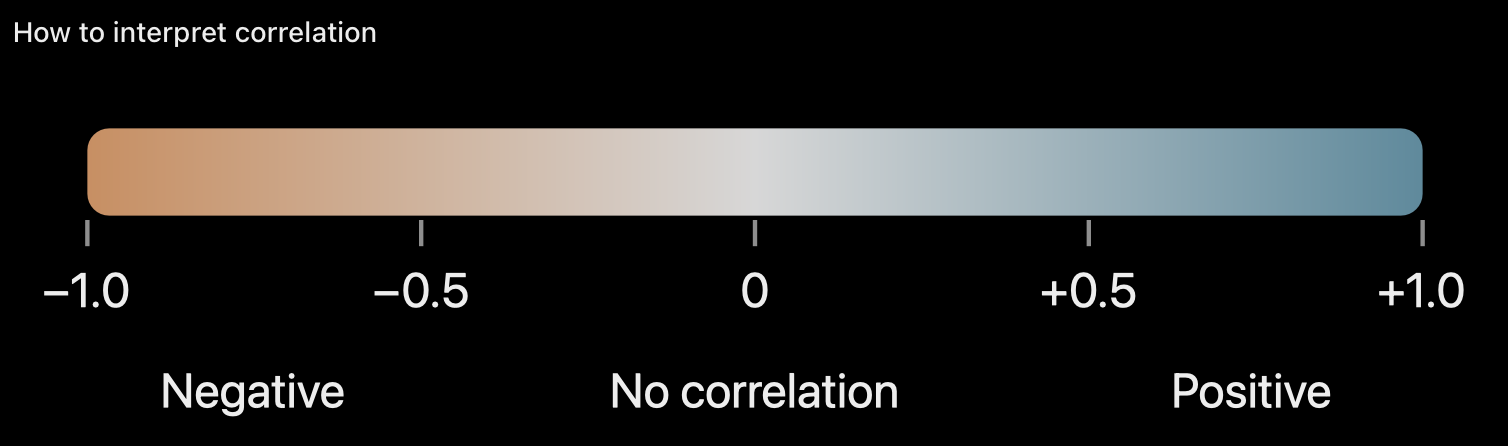

### **Step 4A — Findings and Observations**

Pearson and Spearman correlation analyses were conducted using 1,367 participant-day observations to examine relationships between daily activity measurements and estimated calorie expenditure.

Daily steps showed a moderate positive correlation with estimated calories (Pearson = 0.576; Spearman = 0.550), suggesting that higher-step days generally corresponded to greater estimated energy expenditure.

Steps also showed positive relationships with very active minutes (Pearson = 0.677; Spearman = 0.754), fairly active minutes (Pearson = 0.354; Spearman = 0.701), and lightly active minutes (Pearson = 0.590; Spearman = 0.632).

The difference between Pearson and Spearman correlations for fairly active minutes suggests that the relationship may be influenced by nonlinearity, skewed distributions, or unusual observations.

Daily steps were negatively associated with sedentary minutes (Pearson = -0.351; Spearman = -0.457).

Sedentary minutes showed only a weak negative relationship with estimated calorie expenditure (Pearson = -0.111; Spearman = -0.169).

Overall, the findings suggest that higher daily step counts generally correspond to greater recorded activity intensity and estimated calorie expenditure, while sedentary time tends to decrease.

These correlations describe associations rather than causal relationships. Repeated participant observations and related Fitbit measurement methods should be considered when interpreting the findings.


In [29]:
# ==================================================
# Step 4B.1 - Match Daily Activity and Sleep Records
# ==================================================

# Select relevant daily activity measurements
activity_sleep_data = daily_activity[
    [
        "Id",
        "ActivityDate",
        "TotalSteps",
        "VeryActiveMinutes",
        "FairlyActiveMinutes",
        "LightlyActiveMinutes",
        "SedentaryMinutes"
    ]
].copy()

# Select relevant sleep measurements
sleep_match_data = sleep_trends[
    [
        "Id",
        "SleepEndDate",
        "RecordedHours"
    ]
].copy()

# Standardize dates to remove time components
activity_sleep_data["ActivityDate"] = pd.to_datetime(
    activity_sleep_data["ActivityDate"]
).dt.normalize()

sleep_match_data["SleepEndDate"] = pd.to_datetime(
    sleep_match_data["SleepEndDate"]
).dt.normalize()

# If multiple sleep logs end on the same day,
# retain the longest unflagged log
sleep_match_data = (
    sleep_match_data
    .sort_values("RecordedHours", ascending=False)
    .drop_duplicates(
        subset=["Id", "SleepEndDate"],
        keep="first"
    )
)

# Match sleep logs with daily activity records
activity_sleep_merged = activity_sleep_data.merge(
    sleep_match_data,
    left_on=["Id", "ActivityDate"],
    right_on=["Id", "SleepEndDate"],
    how="inner",
    validate="one_to_one"
)

# Verify matched records
print(
    "Matched observations:",
    len(activity_sleep_merged)
)

print(
    "Unique participants:",
    activity_sleep_merged["Id"].nunique()
)

# Display the first five matched observations
display(activity_sleep_merged.head())


Matched observations: 566
Unique participants: 21


,Id,ActivityDate,TotalSteps,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,SleepEndDate,RecordedHours
0,1503960366,2016-03-25,11004,33,12,205,804,2016-03-25,6.43
1,1503960366,2016-03-26,17609,89,17,274,588,2016-03-26,7.62
2,1503960366,2016-03-27,12736,56,5,268,605,2016-03-27,5.50
3,1503960366,2016-03-29,12041,28,28,243,763,2016-03-29,6.30
4,1503960366,2016-03-31,12256,33,12,239,820,2016-03-31,5.60


In [30]:
# ==================================================
# Step 4B.2 - Activity and Sleep Correlation Analysis
# ==================================================

# Select activity measurements to compare with sleep
sleep_activity_variables = [
    "TotalSteps",
    "VeryActiveMinutes",
    "FairlyActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes"
]

# Create an empty list to store correlation results
sleep_correlation_results = []

# Calculate correlations for each activity measurement
for variable in sleep_activity_variables:

    # Select matched observations with valid measurements
    paired_data = activity_sleep_merged[
        [variable, "RecordedHours"]
    ].dropna()

    # Calculate Pearson correlation
    pearson_corr = paired_data[variable].corr(
        paired_data["RecordedHours"],
        method="pearson"
    )

    # Calculate Spearman correlation
    spearman_corr = paired_data[variable].corr(
        paired_data["RecordedHours"],
        method="spearman"
    )

    # Store the results
    sleep_correlation_results.append({
        "Activity Variable": variable,
        "Sleep Variable": "RecordedHours",
        "Observations": len(paired_data),
        "Pearson": pearson_corr,
        "Spearman": spearman_corr
    })

# Convert results into a DataFrame
sleep_correlation_summary = pd.DataFrame(
    sleep_correlation_results
)

# Round correlation coefficients to three decimals
sleep_correlation_summary = (
    sleep_correlation_summary.round(3)
)

# Display the results
display(sleep_correlation_summary)


,Activity Variable,Sleep Variable,Observations,Pearson,Spearman
0,TotalSteps,RecordedHours,566,-0.081,-0.109
1,VeryActiveMinutes,RecordedHours,566,-0.076,-0.166
2,FairlyActiveMinutes,RecordedHours,566,-0.072,-0.087
3,LightlyActiveMinutes,RecordedHours,566,-0.019,-0.018
4,SedentaryMinutes,RecordedHours,566,-0.487,-0.514


In [31]:
# ==================================================
# Step 4B.3 - Participant-Level Activity and Sleep
# ==================================================

# Calculate average activity and sleep measurements
# for each participant
participant_sleep_activity = (
    activity_sleep_merged
    .groupby("Id")
    .agg(
        MatchedDays=("RecordedHours", "count"),
        AverageSteps=("TotalSteps", "mean"),
        AverageVeryActive=("VeryActiveMinutes", "mean"),
        AverageFairlyActive=("FairlyActiveMinutes", "mean"),
        AverageLightlyActive=("LightlyActiveMinutes", "mean"),
        AverageSedentary=("SedentaryMinutes", "mean"),
        AverageSleepHours=("RecordedHours", "mean")
    )
    .reset_index()
)

# Display participant coverage
print(
    "Participants included:",
    len(participant_sleep_activity)
)

print("\nMatched days per participant:")
display(
    participant_sleep_activity["MatchedDays"].describe().round(2)
)

# Define activity variables to compare with sleep
participant_variables = [
    "AverageSteps",
    "AverageVeryActive",
    "AverageFairlyActive",
    "AverageLightlyActive",
    "AverageSedentary"
]

# Calculate correlations between participant averages
participant_correlation_results = []

for variable in participant_variables:

    paired_data = participant_sleep_activity[
        [variable, "AverageSleepHours"]
    ].dropna()

    # Calculate Pearson and Spearman correlations
    participant_correlation_results.append({
        "Activity Variable": variable,
        "Participants": len(paired_data),
        "Pearson": paired_data[variable].corr(
            paired_data["AverageSleepHours"],
            method="pearson"
        ),
        "Spearman": paired_data[variable].corr(
            paired_data["AverageSleepHours"],
            method="spearman"
        )
    })

# Create and display the comparison table
participant_correlation_summary = pd.DataFrame(
    participant_correlation_results
).round(3)

print("\nParticipant-Level Correlations:")
display(participant_correlation_summary)


Participants included: 21

Matched days per participant:


count    21.00
mean     26.95
std      14.17
min       2.00
25%      20.00
50%      31.00
75%      39.00
max      44.00
Name: MatchedDays, dtype: float64


Participant-Level Correlations:


,Activity Variable,Participants,Pearson,Spearman
0,AverageSteps,21,0.044,0.119
1,AverageVeryActive,21,0.111,0.043
2,AverageFairlyActive,21,-0.146,-0.151
3,AverageLightlyActive,21,-0.080,0.094
4,AverageSedentary,21,-0.884,-0.873


In [32]:
# ==================================================
# Step 4B.4 - Recording Coverage and Sedentary Time
# ==================================================

# Select recording coverage information
recording_coverage = daily_activity[
    ["Id", "ActivityDate", "TotalRecordedMinutes"]
].copy()

# Add recording coverage to matched activity-sleep data
activity_sleep_coverage = activity_sleep_merged.merge(
    recording_coverage,
    on=["Id", "ActivityDate"],
    how="left",
    validate="one_to_one"
)

# Calculate the proportion of recorded activity
# minutes classified as sedentary
activity_sleep_coverage["SedentaryShare"] = (
    activity_sleep_coverage["SedentaryMinutes"]
    / activity_sleep_coverage["TotalRecordedMinutes"].replace(0, np.nan)
)

# Calculate participant-level averages
coverage_profiles = (
    activity_sleep_coverage
    .groupby("Id")
    .agg(
        MatchedDays=("RecordedHours", "count"),
        AvgSleepHours=("RecordedHours", "mean"),
        AvgSedentaryMinutes=("SedentaryMinutes", "mean"),
        AvgRecordedMinutes=("TotalRecordedMinutes", "mean"),
        AvgSedentaryShare=("SedentaryShare", "mean")
    )
)

# Compare relationships with recorded sleep duration
coverage_variables = [
    "AvgSedentaryMinutes",
    "AvgRecordedMinutes",
    "AvgSedentaryShare"
]

coverage_results = []

for variable in coverage_variables:

    paired_data = coverage_profiles[
        [variable, "AvgSleepHours"]
    ].dropna()

    coverage_results.append({
        "Variable": variable,
        "Participants": len(paired_data),
        "Pearson": paired_data[variable].corr(
            paired_data["AvgSleepHours"],
            method="pearson"
        ),
        "Spearman": paired_data[variable].corr(
            paired_data["AvgSleepHours"],
            method="spearman"
        )
    })

# Display correlations
coverage_summary = pd.DataFrame(
    coverage_results
).round(3)

display(coverage_summary)

# Check recording coverage and sample size
print("Missing recording totals:",
      activity_sleep_coverage["TotalRecordedMinutes"].isna().sum())

print("Participant recording coverage:")
display(
    coverage_profiles[
        ["MatchedDays", "AvgRecordedMinutes"]
    ].describe().round(2)
)


,Variable,Participants,Pearson,Spearman
0,AvgSedentaryMinutes,21,-0.884,-0.873
1,AvgRecordedMinutes,21,-0.974,-0.949
2,AvgSedentaryShare,21,-0.396,-0.610


Missing recording totals: 0
Participant recording coverage:


,MatchedDays,AvgRecordedMinutes
count,21.00,21.00
mean,26.95,1003.31
std,14.17,111.95
min,2.00,898.32
25%,20.00,943.17
50%,31.00,975.20
75%,39.00,1028.33
max,44.00,1311.67


### **Step 4B — Findings and Observations**

Daily activity and sleep data were matched using participant identifiers and sleep-end dates, producing 566 matched observations from 21 participants.

Pearson and Spearman correlations showed very weak relationships between recorded sleep-log duration and daily steps, very active minutes, fairly active minutes, and lightly active minutes.

Sedentary minutes showed a moderate negative relationship with recorded sleep duration (Pearson = -0.487; Spearman = -0.514).

Participant-level analysis revealed a stronger negative correlation between average sedentary minutes and average sleep duration (Pearson = -0.884; Spearman = -0.873).

However, further examination showed an even stronger negative relationship between total recorded activity minutes and sleep duration (Pearson = -0.974; Spearman = -0.949).

When sedentary time was expressed as a proportion of total recorded activity minutes, the Pearson correlation weakened to -0.396, while Spearman was -0.610.

These findings suggest that differences in recording coverage and the allocation of daily time may contribute to the observed relationship between sedentary minutes and sleep duration.

Overall, daily physical activity measurements showed little association with recorded sleep-log duration, while sedentary time showed a stronger negative association that requires cautious interpretation.

These results do not establish causation. Potential measurement relationships, unequal recording coverage, and the limited number of participants should be considered before using these findings to inform Bellabeat's marketing strategy.


In [33]:
# ==================================================
# Step 4C - Examine Daily Time Accounting
# ==================================================

# Create a copy of the matched dataset
time_accounting = activity_sleep_coverage.copy()

# Convert recorded sleep hours into minutes
time_accounting["SleepMinutes"] = (
    time_accounting["RecordedHours"] * 60
)

# Calculate combined activity and sleep minutes
time_accounting["CombinedMinutes"] = (
    time_accounting["TotalRecordedMinutes"]
    + time_accounting["SleepMinutes"]
)

# Compare combined minutes with a 24-hour day
time_accounting["DifferenceFrom1440"] = (
    time_accounting["CombinedMinutes"] - 1440
)

# Calculate descriptive statistics
time_accounting_summary = time_accounting[
    [
        "TotalRecordedMinutes",
        "SleepMinutes",
        "CombinedMinutes",
        "DifferenceFrom1440"
    ]
].describe().round(2)

# Display the summary
display(time_accounting_summary.T)

# Count observations close to 1440 minutes
within_15_minutes = (
    time_accounting["DifferenceFrom1440"].abs() <= 15
).sum()

print(
    "Observations within 15 minutes of 1440:",
    within_15_minutes
)

print(
    "Total matched observations:",
    len(time_accounting)
)

print(
    "Percentage within 15 minutes:",
    f"{within_15_minutes / len(time_accounting) * 100:.2f}%"
)


,count,mean,std,min,25%,50%,75%,max
TotalRecordedMinutes,566.0,966.28,141.88,2.0,914.25,982.5,1034.75,1398.0
SleepMinutes,566.0,442.67,102.99,121.2,384.00,451.8,510.00,751.2
CombinedMinutes,566.0,1408.95,123.22,323.0,1394.90,1439.8,1453.65,1662.2
DifferenceFrom1440,566.0,-31.05,123.22,-1117.0,-45.10,-0.2,13.65,222.2


Observations within 15 minutes of 1440: 231
Total matched observations: 566
Percentage within 15 minutes: 40.81%


### **Step 4C — Findings and Observations**

A daily time-accounting analysis was conducted using 566 matched activity and sleep observations to investigate whether the strong negative relationship between sedentary minutes and recorded sleep duration could be influenced by how Fitbit classifies recorded time.

Average recorded activity time was 966.28 minutes, while average recorded sleep-log duration was 442.67 minutes. The mean combined duration was 1,408.95 minutes, compared with a median of 1,439.80 minutes.

Of the 566 observations, 231 (40.81%) had combined durations within 15 minutes of a 24-hour day.

These results suggest that recorded activity and sleep durations may account for complementary portions of daily time, potentially contributing to the strong negative correlations observed previously.

However, combined durations varied considerably, indicating that recording coverage, sleep timing, and measurement definitions may also influence the results.

Overall, the relationship between sedentary time and recorded sleep duration should be interpreted cautiously. The strong negative correlation may partly reflect how recorded time is allocated rather than an independent behavioral relationship.

For this reason, the sedentary-and-sleep correlation will not be emphasized as a primary behavioral finding for Bellabeat without additional supporting analysis.


In [34]:
# ==================================================
# Step 4D - Participant-Level Steps and Calories
# ==================================================

# Calculate each participant's average daily steps
# and estimated calorie expenditure
participant_calorie_profiles = (
    daily_calories
    .groupby("Id")
    .agg(
        RecordedDays=("TotalSteps", "count"),
        AverageSteps=("TotalSteps", "mean"),
        AverageCalories=("Calories", "mean")
    )
    .reset_index()
)

# Calculate between-participant correlations
between_pearson = participant_calorie_profiles[
    "AverageSteps"
].corr(
    participant_calorie_profiles["AverageCalories"],
    method="pearson"
)

between_spearman = participant_calorie_profiles[
    "AverageSteps"
].corr(
    participant_calorie_profiles["AverageCalories"],
    method="spearman"
)

# Create a copy for within-participant analysis
within_data = daily_calories[
    ["Id", "TotalSteps", "Calories"]
].copy()

# Subtract each participant's average from
# their individual daily measurements
within_data["StepsDeviation"] = (
    within_data["TotalSteps"]
    - within_data.groupby("Id")["TotalSteps"].transform("mean")
)

within_data["CaloriesDeviation"] = (
    within_data["Calories"]
    - within_data.groupby("Id")["Calories"].transform("mean")
)

# Calculate the pooled within-participant
# Pearson correlation
within_pearson = within_data[
    "StepsDeviation"
].corr(
    within_data["CaloriesDeviation"]
)

# Organize correlation results
comparison_summary = pd.DataFrame({
    "Analysis": [
        "All Participant-Days",
        "Between Participants",
        "Within Participants"
    ],
    "Pearson": [
        daily_calories["TotalSteps"].corr(
            daily_calories["Calories"]
        ),
        between_pearson,
        within_pearson
    ]
}).round(3)

# Display results
display(comparison_summary)

# Display participant recording coverage
print("Total participants:", len(participant_calorie_profiles))

print("\nRecorded days per participant:")
display(
    participant_calorie_profiles[
        "RecordedDays"
    ].describe().round(2)
)

print(
    f"\nBetween-participant Spearman: "
    f"{between_spearman:.3f}"
)


,Analysis,Pearson
0,All Participant-Days,0.576
1,Between Participants,0.432
2,Within Participants,0.802


Total participants: 35

Recorded days per participant:


count    35.00
mean     39.06
std       9.49
min       8.00
25%      37.50
50%      42.00
75%      42.00
max      62.00
Name: RecordedDays, dtype: float64


Between-participant Spearman: 0.350


### **Step 4D — Findings and Observations**

Relationships between daily steps and estimated calorie expenditure were examined at the participant-day, between-participant, and within-participant levels.

The overall Pearson correlation was 0.576, indicating a moderate positive association between daily steps and estimated calorie expenditure.

The between-participant Pearson correlation was 0.432, while Spearman was 0.350, indicating a weaker positive relationship between participants' average activity levels and estimated calorie expenditure.

The strongest relationship occurred within participants, with a pooled Pearson correlation of 0.802. This suggests that days with higher-than-usual step counts generally corresponded to higher-than-usual estimated calorie expenditure for the same participant.

Recording coverage varied across the 35 participants, ranging from 8 to 62 recorded days.

Overall, the findings suggest that individual changes in activity may provide useful information for personalized wellness tracking.

However, estimated calorie expenditure is partly derived from activity-related measurements, and the observed correlations do not establish causation. Differences in participant recording coverage should also be considered.


## **Step 5: Interpret Findings for Bellabeat**

### Purpose
To identify the most important trends and relationships discovered during the analysis and evaluate how they could inform Bellabeat's understanding of smart-device users.

### Approach
- Review the strongest findings from the descriptive and relationship analyses.
- Identify patterns relevant to physical activity, sleep, and wellness tracking.
- Connect the findings to potential Bellabeat customer needs.
- Evaluate potential applications to a Bellabeat product.
- Consider the limitations of the Fitbit sample when interpreting results.

### Expected Outcome
A concise summary of evidence-based insights that addresses the original business questions and supports potential marketing recommendations in the Act Phase.


In [35]:
# ==================================================
# Step 5A - Summarize Key Analytical Findings
# ==================================================

# Calculate the percentage of participants
# averaging fewer than 7,500 steps
low_step_count = participant_activity[
    "ActivityGroup"
].isin([
    "Under 5,000",
    "5,000-7,499"
]).sum()

low_step_pct = (
    low_step_count / len(participant_activity) * 100
)

# Identify the hour with the highest average steps
peak_hour = hourly_step_summary[
    "AverageSteps"
].idxmax()

# Calculate average steps for the peak hour
peak_steps = hourly_step_summary.loc[
    peak_hour, "AverageSteps"
]

# Organize the strongest findings into a table
key_findings = pd.DataFrame([
    {
        "Finding": "Average Daily Steps",
        "Result": (
            f"{daily_activity['TotalSteps'].mean():,.2f} steps"
        )
    },
    {
        "Finding": "Participants Averaging Under 7,500 Steps",
        "Result": f"{low_step_pct:.2f}%"
    },
    {
        "Finding": "Peak Hourly Step Activity",
        "Result": (
            f"{int(peak_hour):02d}:00 "
            f"({peak_steps:,.2f} steps)"
        )
    },
    {
        "Finding": "Average Unflagged Sleep-Log Duration",
        "Result": (
            f"{sleep_trends['RecordedHours'].mean():.2f} hours"
        )
    },
    {
        "Finding": "Mean Within-Participant Weekend Step Difference",
        "Result": (
            f"{participant_steps['Difference'].mean():+.2f} steps"
        )
    },
    {
        "Finding": "Within-Participant Steps-Calorie Correlation",
        "Result": f"{within_pearson:.3f}"
    }
])

# Display the summary
display(key_findings)


,Finding,Result
0,Average Daily Steps,"7,377.38 steps"
1,"Participants Averaging Under 7,500 Steps",57.14%
2,Peak Hourly Step Activity,19:00 (554.89 steps)
3,Average Unflagged Sleep-Log Duration,6.93 hours
4,Mean Within-Participant Weekend Step Difference,-206.45 steps
5,Within-Participant Steps-Calorie Correlation,0.802


### **Step 5A — Findings and Observations**

The major findings from the descriptive statistics, usage-trend analysis, and correlation analysis were consolidated into a summary table.

Fitbit participants averaged 7,377.38 daily steps, while 57.14% averaged fewer than 7,500 steps. These results highlight differences in physical activity across participants.

Average hourly step counts were highest at 7 PM, suggesting that early evening was a period of relatively high recorded physical activity.

Unflagged sleep logs averaged 6.93 hours, indicating that sleep tracking provides additional information about recorded wellness behaviors.

Participant-level analysis showed approximately 206 fewer steps on weekends, on average, although individual patterns varied.

The within-participant correlation between daily steps and estimated calorie expenditure was 0.802, indicating a strong positive association.

Overall, these findings suggest potential opportunities for personalized activity tracking, individual progress monitoring, and sleep-related wellness features.

However, the analysis is based on historical Fitbit data from a limited sample. These findings cannot automatically be generalized to Bellabeat customers.


In [36]:

# ==================================================
# Step 5B - Connect Findings to Business Questions
# ==================================================

# Create a table linking analytical findings to potential Bellabeat Time applications
business_insights = pd.DataFrame([
    {
        "Finding": "Differences in daily activity",
        "Evidence": (
            f"{low_step_pct:.2f}% of participants averaged "
            "fewer than 7,500 daily steps"
        ),
        "Potential Application": (
            "Explore personalized activity goals "
            "for users with different activity levels"
        )
    },
    {
        "Finding": "Hourly activity patterns",
        "Evidence": (
            f"Peak average activity at {int(peak_hour):02d}:00"
        ),
        "Potential Application": (
            "Explore activity reminders based "
            "on individual daily routines"
        )
    },
    {
        "Finding": "Recorded sleep patterns",
        "Evidence": (
            f"Average unflagged sleep-log duration: "
            f"{sleep_trends['RecordedHours'].mean():.2f} hours"
        ),
        "Potential Application": (
            "Explore personalized sleep tracking "
            "and wellness education"
        )
    },
    {
        "Finding": "Individual activity changes",
        "Evidence": (
            f"Within-participant steps-calorie "
            f"correlation: {within_pearson:.3f}"
        ),
        "Potential Application": (
            "Explore personal progress tracking "
            "rather than relying only on "
            "comparisons between users"
        )
    }
])

# Display the business interpretation table
display(business_insights)

,Finding,Evidence,Potential Application
0,Differences in daily activity,"57.14% of participants averaged fewer than 7,5...",Explore personalized activity goals for users ...
1,Hourly activity patterns,Peak average activity at 19:00,Explore activity reminders based on individual...
2,Recorded sleep patterns,Average unflagged sleep-log duration: 6.93 hours,Explore personalized sleep tracking and wellne...
3,Individual activity changes,Within-participant steps-calorie correlation: ...,Explore personal progress tracking rather than...


### **Step 5B — Findings and Observations**

The key analytical findings were connected to potential business applications for Bellabeat, focusing on the Time wellness watch.

Four potential opportunities were identified: personalized activity goals, activity reminders based on individual routines, sleep tracking and wellness education, and personalized progress monitoring.

Differences in daily step counts suggest that users may benefit from activity goals tailored to their individual activity levels.

Higher recorded activity during early evening hours suggests an opportunity to explore activity reminders that adapt to individual routines rather than following a fixed schedule.

Recorded sleep patterns highlight the potential value of sleep monitoring and personalized wellness education.

The strong within-participant relationship between daily steps and estimated calorie expenditure also supports exploring personal progress tracking over time.

Overall, the findings suggest opportunities for Bellabeat to emphasize personalized wellness experiences in its product positioning and marketing.

However, these applications are exploratory. The dataset contains historical Fitbit observations rather than Bellabeat customer data, and additional research would be necessary to validate customer needs and marketing effectiveness.


## **Step 6: Export Analytical Summaries**

### Purpose
To export the analytical results into organized CSV files that can be used for visualizations, reporting, and project documentation.

In [38]:
# ==================================================
# Step 6A - Export Analytical Summary Tables
# ==================================================

# Define the folder for analytical outputs
output_dir = project_dir / "Analysis_Outputs"

# Create the folder if it does not already exist
output_dir.mkdir(parents=True, exist_ok=True)

# Organize the summary tables for export
# Reset indexes to preserve weekday, hour, and
# activity group labels as regular CSV columns
summary_exports = {
    "weekday_steps.csv": weekday_summary.reset_index(),

    "hourly_steps.csv": hourly_step_summary.reset_index(),

    "hourly_intensity.csv": hourly_intensity_summary.reset_index(),

    "hourly_calories.csv": hourly_calorie_summary.reset_index(),

    "sleep_by_weekday.csv": sleep_weekday_summary.reset_index(),

    "activity_groups.csv": activity_group_summary.reset_index(),

    "activity_group_profiles.csv": activity_profile_summary.reset_index(),

    "daily_activity_correlations.csv": correlation_summary,

    "key_findings.csv": key_findings,

    "business_insights.csv": business_insights
}

# Export each summary table as a CSV file
for filename, df in summary_exports.items():

    file_path = output_dir / filename

    # Save without the Pandas row index
    df.to_csv(file_path, index=False)

    print(f"Exported: {filename} ({len(df)} rows)")

# Confirm the number of exported files
print("\nTotal files exported:", len(summary_exports))

# Display the export folder
print("\nOutput folder:")
print(output_dir)


Exported: weekday_steps.csv (7 rows)
Exported: hourly_steps.csv (24 rows)
Exported: hourly_intensity.csv (24 rows)
Exported: hourly_calories.csv (24 rows)
Exported: sleep_by_weekday.csv (7 rows)
Exported: activity_groups.csv (4 rows)
Exported: activity_group_profiles.csv (4 rows)
Exported: daily_activity_correlations.csv (7 rows)
Exported: key_findings.csv (6 rows)
Exported: business_insights.csv (4 rows)

Total files exported: 10

Output folder:
/Users/isandoval/Desktop/Bellabeat_Case_Study/Analysis_Outputs


In [39]:
# ==================================================
# Step 6B - Verify Exported CSV Files
# ==================================================

# Create an empty list to store verification results
validation_results = []

# Verify each exported CSV file
for filename, original_df in summary_exports.items():

    # Locate the exported file
    file_path = output_dir / filename

    try:
        # Reload the exported CSV into Pandas
        reloaded_df = pd.read_csv(file_path)

        # Verify dimensions and column names
        rows_match = len(reloaded_df) == len(original_df)

        columns_match = (
            reloaded_df.columns.tolist()
            == original_df.columns.tolist()
        )

        # Compare the reloaded values with the originals
        try:
            pd.testing.assert_frame_equal(
                original_df.reset_index(drop=True),
                reloaded_df,
                check_dtype=False,
                check_categorical=False,
                check_exact=False,
                rtol=1e-8,
                atol=1e-8
            )
            values_match = True

        except AssertionError:
            values_match = False

        # Assign a verification status
        status = (
            "PASS"
            if rows_match and columns_match and values_match
            else "REVIEW"
        )

        # Store the results
        validation_results.append({
            "File": filename,
            "Expected Rows": len(original_df),
            "Actual Rows": len(reloaded_df),
            "Columns Match": columns_match,
            "Values Match": values_match,
            "Status": status
        })

    except (OSError, ValueError, pd.errors.ParserError) as error:

        # Record files that cannot be opened
        validation_results.append({
            "File": filename,
            "Expected Rows": len(original_df),
            "Actual Rows": None,
            "Columns Match": False,
            "Values Match": False,
            "Status": "ERROR"
        })

# Create the verification summary
validation_summary = pd.DataFrame(validation_results)

# Display the results
display(validation_summary)

# Count successfully verified files
passed_files = (
    validation_summary["Status"] == "PASS"
).sum()

print(
    f"\nFiles successfully verified: "
    f"{passed_files} of {len(summary_exports)}"
)

,File,Expected Rows,Actual Rows,Columns Match,Values Match,Status
0,weekday_steps.csv,7,7,True,True,PASS
1,hourly_steps.csv,24,24,True,True,PASS
2,hourly_intensity.csv,24,24,True,True,PASS
3,hourly_calories.csv,24,24,True,True,PASS
4,sleep_by_weekday.csv,7,7,True,True,PASS
5,activity_groups.csv,4,4,True,True,PASS
6,activity_group_profiles.csv,4,4,True,True,PASS
7,daily_activity_correlations.csv,7,7,True,True,PASS
8,key_findings.csv,6,6,True,True,PASS
9,business_insights.csv,4,4,True,True,PASS



Files successfully verified: 10 of 10


### **Step 6B — Findings and Observations**

Ten analytical summary tables were successfully exported as CSV files and stored in the Analysis_Outputs folder.

Each exported file was reloaded into Python and compared with its original DataFrame to verify row counts, column names, and values.

All 10 files passed validation, with no discrepancies identified within the specified comparison tolerances.

The exported datasets are ready to support Tableau visualizations, project documentation, and the final data analysis report.


## **Analyze Phase — Conclusion**

### Summary of Key Findings

The analysis identified several important patterns in Fitbit users' physical activity, estimated calorie expenditure, and recorded sleep duration.

1. **Daily Activity:** Participants averaged 7,377 steps per recorded day, while 57.14% averaged fewer than 7,500 daily steps.

2. **Hourly Activity Patterns:** Physical activity was generally lowest overnight and highest during midday and early evening. Average hourly steps peaked at 7 PM.

3. **Activity Differences:** Participants demonstrated considerable variation in daily step counts, active minutes, and sedentary behavior, highlighting differences in individual activity patterns.

4. **Sleep Patterns:** Unflagged sleep logs averaged 6.93 recorded hours. Sleep-log durations varied throughout the week, particularly on weekends.

5. **Activity and Calorie Relationships:** Daily steps and estimated calorie expenditure showed a strong positive within-participant correlation (r = 0.802), suggesting that higher-than-usual step counts generally corresponded with higher-than-usual estimated calorie expenditure.

### Business Implications

The findings suggest potential opportunities for Bellabeat to explore personalized activity goals, routine-based reminders, sleep tracking, and individual progress monitoring.

These opportunities could help inform product positioning and marketing strategies for the Bellabeat Time wellness watch.

### Analysis Limitations

The analysis used historical Fitbit data rather than direct Bellabeat customer data.

The number of participants varied across datasets, and some participants contributed more observations than others. Recording gaps, unusual measurements, and differences in device usage may also influence the results.

Additionally, recorded sleep-log duration does not necessarily represent actual time asleep, and correlations do not establish causal relationships.

### Final Outcome

The Analyze Phase successfully identified trends, differences, and relationships in smart-device usage.

Ten analytical summary tables were exported as CSV files and successfully validated.

These outputs will be used during the Share Phase to create visualizations and communicate findings to Bellabeat stakeholders.
